# Lesson 7: Linear regression from scratch

Predict median home values in the historical Boston housing dataset. Compare a NumPy implementation of batch gradient descent with scikit-learn’s ordinary least squares on the same test split. Run from this folder with NumPy, pandas, Matplotlib, and scikit-learn installed.

**Data:** [Boston Housing](https://www.kaggle.com/datasets/vikrishnan/boston-house-prices). Download `housing.csv` and place it in this lesson folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
df = pd.read_csv('housing.csv', header=None, delimiter=r"\s+", names=column_names)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


## Prepare the data

Split the rows before preprocessing. For selected features, cap extreme values at three interquartile ranges beyond the first and third quartiles. Estimate those bounds and the scaling parameters from the training split, then reuse them for the test split. The historical race-derived column `B` is excluded from the model.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

features = df.drop(columns=["MEDV", "B"])
X_train, X_test, y_train, y_test = train_test_split(
    features, df["MEDV"], test_size=0.2, random_state=42
)

clip_columns = ["CRIM", "TAX", "LSTAT", "DIS"]
q1 = X_train[clip_columns].quantile(0.25)
q3 = X_train[clip_columns].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 3 * iqr, q3 + 3 * iqr

for split in (X_train, X_test):
    split[clip_columns] = split[clip_columns].clip(lower, upper, axis="columns")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Fit the models

At each step, compute the prediction errors for the whole training batch. Use those errors to update the weights and intercept in the direction that reduces mean squared error.

In [3]:
from sklearn.linear_model import LinearRegression

class MyLinearRegression:
    def __init__(self, lr=0.01, iterations=5000):
        self.lr = lr
        self.iterations = iterations

    def fit(self, X, y):
        self.weights = np.zeros(X.shape[1])
        self.intercept = 0.0
        y = np.asarray(y)
        for _ in range(self.iterations):
            errors = self.predict(X) - y
            self.weights -= self.lr * (2 / len(X)) * (X.T @ errors)
            self.intercept -= self.lr * 2 * errors.mean()
        return self

    def predict(self, X):
        return X @ self.weights + self.intercept

gradient_descent = MyLinearRegression().fit(X_train_scaled, y_train)
least_squares = LinearRegression().fit(X_train_scaled, y_train)
predictions = {
    "Gradient descent": gradient_descent.predict(X_test_scaled),
    "Ordinary least squares": least_squares.predict(X_test_scaled),
}

## Evaluate on the test split

Compare mean squared error and R². The diagonal in the plot marks an exact prediction. `MEDV` is measured in thousands of dollars.

In [4]:
from sklearn.metrics import mean_squared_error, r2_score

pd.DataFrame({
    name: {"MSE": mean_squared_error(y_test, pred), "R²": r2_score(y_test, pred)}
    for name, pred in predictions.items()
}).T

,MSE,R²
Gradient descent,22.266213,0.696372
Ordinary least squares,22.259465,0.696464


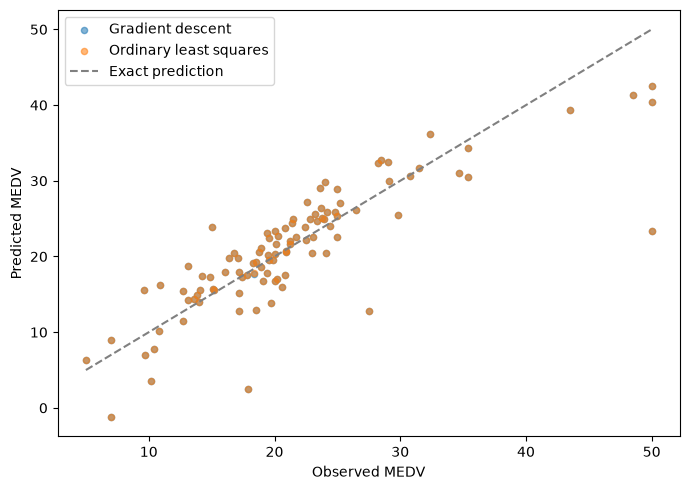

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, pred in predictions.items():
    ax.scatter(y_test, pred, label=name, alpha=0.55, s=20)
limits = [y_test.min(), y_test.max()]
ax.plot(limits, limits, "--", color="gray", label="Exact prediction")
ax.set(xlabel="Observed MEDV", ylabel="Predicted MEDV")
ax.legend()
fig.tight_layout()
plt.show()